## Exploratory Data Analysis - Credit-Risk Dataset
* **Source:** UCI Machine Learning Repository (Default of Credit Card Clients)[cite: 6].
* **Access Date:** 2026-10-03[cite: 6].
* **Observation Unit:** One borrower credit-card account record (30,000 εγγραφές)[cite: 6].
* **Target:** `default payment next month` (Binary: 1 = default, 0 = no default)[cite: 6].
* **Units:** New Taiwan dollars (NTD) για όρια και ποσά, έτη για την ηλικία[cite: 6].

=== DATA AUDIT ===
Shape: (30000, 25)
Duplicate rows: 0
Missing values sum: 0

Target Balance:
default payment next month
0    23364
1     6636
Name: count, dtype: int64
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64

=== DESCRIPTIVE STATISTICS ===
            LIMIT_BAL           AGE      BILL_AMT1       PAY_AMT1  \
count    30000.000000  30000.000000   30000.000000   30000.000000   
mean    167484.322667     35.485500   51223.330900    5663.580500   
std     129747.661567      9.217904   73635.860576   16563.280354   
min      10000.000000     21.000000 -165580.000000       0.000000   
25%      50000.000000     28.000000    3558.750000    1000.000000   
50%     140000.000000     34.000000   22381.500000    2100.000000   
75%     240000.000000     41.000000   67091.000000    5006.000000   
max    1000000.000000     79.000000  964511.000000  873552.000000   

              PAY_0  default payment next month  
count  30000.000000                30000.000

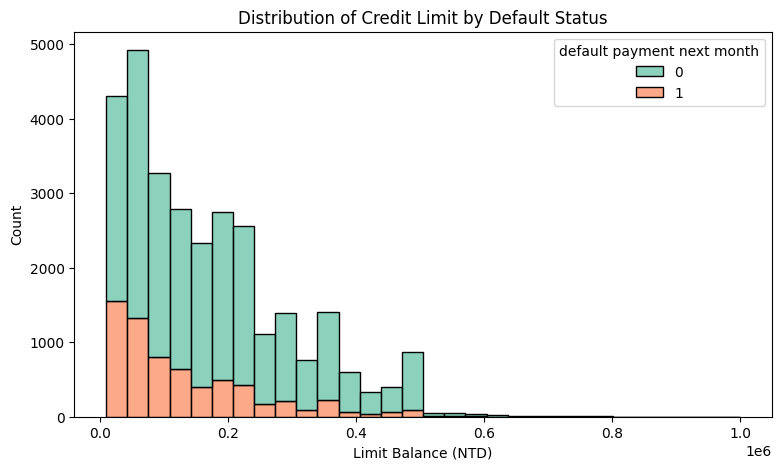

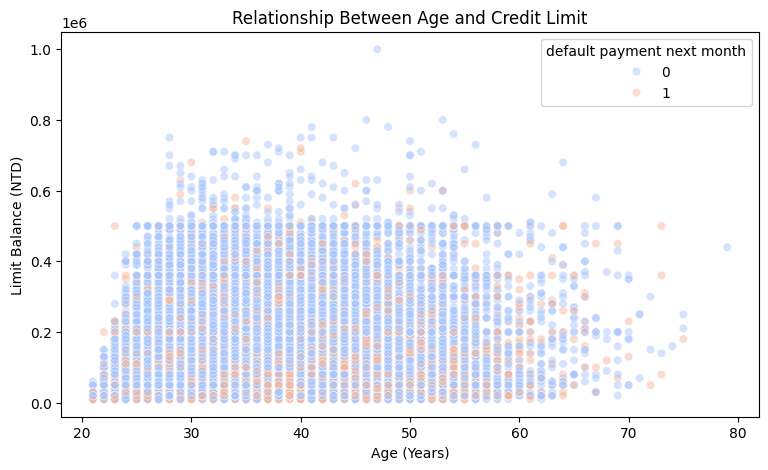

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Φόρτωση δεδομένων
df = pd.read_csv('default_of_credit_card_clients.csv.gz', compression='gzip', header=0)

# Data Audit
print("=== DATA AUDIT ===")
print(f"Shape: {df.shape}")
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Missing values sum: {df.isnull().sum().sum()}")

print("\nTarget Balance:")
print(df['default payment next month'].value_counts())
print(df['default payment next month'].value_counts(normalize=True) * 100)

# Descriptive Statistics (6 μεταβλητές)
selected_vars = ['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'PAY_AMT1', 'PAY_0', 'default payment next month']
print("\n=== DESCRIPTIVE STATISTICS ===")
print(df[selected_vars].describe())

# Groupby Comparison
print("\n=== GROUPBY SUMMARY ===")
groupby_summary = df.groupby(['EDUCATION', 'MARRIAGE']).agg(
    Client_Count=('ID', 'count'),
    Default_Rate=('default payment next month', 'mean'),
    Mean_Limit=('LIMIT_BAL', 'mean')
).reset_index()
print(groupby_summary)

# Διάγραμμα 1: Κατανομή Ορίου Πίστωσης ανά Default
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='LIMIT_BAL', hue='default payment next month', multiple='stack', bins=30, palette='Set2')
plt.title("Distribution of Credit Limit by Default Status")
plt.xlabel("Limit Balance (NTD)")
plt.ylabel("Count")
plt.show()

# Διάγραμμα 2: Σχέση Ηλικίας και Ορίου Πίστωσης
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='AGE', y='LIMIT_BAL', hue='default payment next month', alpha=0.5, palette='coolwarm')
plt.title("Relationship Between Age and Credit Limit")
plt.xlabel("Age (Years)")
plt.ylabel("Limit Balance (NTD)")
plt.show()

### Ερμηνεία Διαγραμμάτων
* **Διάγραμμα 1:** Οι πελάτες με χαμηλότερα όρια πίστωσης (`LIMIT_BAL`) παρουσιάζουν μεγαλύτερη συχνότητα και αναλογία αθέτησης πληρωμών (`default = 1`), γεγονός που δείχνει πως ο πιστωτικός κίνδυνος κατανέμεται εντονότερα στα χαμηλότερα όρια.
* **Διάγραμμα 2:** Τα υψηλότερα πιστωτικά όρια συγκεντρώνουν κυρίως μεσαίες ηλικιακές ομάδες (30–50 ετών), ενώ οι περιπτώσεις default εμφανίζονται διασκορπισμένες σε όλο το ηλικιακό φάσμα.

### Περιορισμοί & Μη Αιτιότητα
* **Data-Quality Limitation:** Οι μεταβλητές κατάστασης πληρωμών (`PAY_0` έως `PAY_6`) εμπεριέχουν ειδικούς κωδικούς (όπως `0` και `-2`) πέρα από τις τυπικές τιμές της UCI, οι οποίοι απαιτούν προσεκτική τεκμηρίωση και αναδιατύπωση πριν από οποιαδήποτε μοντελοποίηση[cite: 6].
* **Non-Causality:** Η ανάλυση βασίζεται σε παρατηρησιακά δεδομένα (observational data) και δεν μπορεί να αποδείξει αιτιώδη συνάρτηση (causality), καθώς το ιστορικό πληρωμών ή το όριο πίστωσης δεν προκαλούν με βεβαιότητα το μελλοντικό default ανεξάρτητα από εξωτερικούς οικονομικούς παράγοντες.